# 01. Имперская лексика

Основные политические термины: *imperialism*, *imperialist*, *imperialists*, *jingoism*. Общая имперская лексика: *imperial*, *empire*. Титулатура: *emperor*, *empress*. Дополнительно *jingo*, *czar*, *tsar*, *russia*, *russian*, *russophobia*, *autocracy* для качественного анализа. Используем только модели 2023 года и фиксированные наборы слов. Пропуск — не ноль. Ранние редкие словоформы требуют проверки по первоисточникам.

In [1]:
import importlib
from pathlib import Path
from lwm import config as C, tools as T
C = importlib.reload(C)
T = importlib.reload(T)
expected_module = Path.cwd() / "lwm" / "tools.py"
if expected_module.is_file() and Path(T.__file__).resolve() != expected_module.resolve():
    raise RuntimeError("Модуль lwm.tools загружен не из текущего репозитория. Проверьте рабочий каталог Jupyter.")
required_tools = ['load_cache', 'field_balance', 'save_table', 'set_style']
required_config = ['BALANCE_TARGETS', 'OWN', 'FOREIGN']
missing_tools = [name for name in required_tools if not hasattr(T, name)]
missing_config = [name for name in required_config if not hasattr(C, name)]
if missing_tools or missing_config:
    raise RuntimeError(
        f"Несовместимые файлы проекта: отсутствуют функции {missing_tools} и настройки {missing_config}. "
        "Проверьте, что ноутбуки и папка lwm относятся к одной версии репозитория."
    )

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)
T.set_style()
cache = T.load_cache()
V = cache["vectors"]
x = np.arange(len(C.PERIODS))
LABS = T.decade_labels()


## 1. Ближайшие соседи и OCR

Сохраняем исходный Top-200. По примеру Pedrazzini, McGillivray (2022, Appendix B) фильтруем только списки соседей, не меняя векторы. `pyspellchecker` выявляет формы, отсутствующие в современном английском словаре, но **не исключает их автоматически**. Исторические имена и написания могут отсутствовать в словаре; ошибки OCR могут совпадать с настоящими словами.

`ocr_exclusions.csv` — прежние точные правила (в том числе локальные). `ocr_review.csv` — создаваемая таблица диагностики и постоянных экспертных решений. Редактируйте в ней только `decision` (`keep`, `exclude`, `review` или пусто) и `decision_reason` (обязательно для `keep`/`exclude`). Решение `exclude` действует на эту форму во всех периодах и списках; неоднозначные локальные исключения добавляйте в `ocr_exclusions.csv`. `keep` не отменяет старое точное правило — конфликт отмечается в таблице. Нерассмотренные формы остаются в списках. После каждого редактирования сохраните и закройте CSV, затем повторите ячейки раздела 1; новые кандидаты автоматически получат приоритет. Не редактируйте производные CSV в `results/tables`.

Результаты диагностики сохраняются вместе с решениями; при повторном запуске решения не сбрасываются. Диагностика и исключения не меняют количественные расчёты разделов 2–3. Top-30 после исключений — кандидаты для интерпретации, а не гарантированно безошибочный словарь.

In [2]:
# Орфографическая диагностика и сохранение экспертных решений.
# Установка в текущем ядре при необходимости: %pip install pyspellchecker==0.8.3
from importlib.metadata import version
try:
    from spellchecker import SpellChecker
except ImportError as exc:
    raise ImportError("Установите pyspellchecker в окружение Jupyter: %pip install pyspellchecker==0.8.3") from exc
from lwm import ocr_review as OCR
OCR = importlib.reload(OCR)

SUGGEST_CORRECTIONS = True  # подсказки только для непроверенных неизвестных слов в текущих Top-30
SPELL_DISTANCE = 1  # 2 — более широкий, но более медленный поиск исправлений
review_path = C.ROOT / "ocr_review.csv"
decisions = OCR.load_decisions(review_path)
base_rules = T.read_ocr_rules()
rules = OCR.effective_rules(base_rules, decisions)
review = T.neighbor_review(cache, rules)
spell = SpellChecker(language="en", distance=SPELL_DISTANCE)
diagnostic = OCR.diagnose(review, decisions, spell, topn=C.REPORT_TOPN,
                         suggest=SUGGEST_CORRECTIONS, dictionary_version=version("pyspellchecker"),
                         distance=SPELL_DISTANCE)
OCR.save_review(diagnostic, review_path)
priority = diagnostic[diagnostic["priority"].isin(["unknown_top30", "check_top30"])].copy()
T.save_table(priority, "03_ocr_priority", index=False)
T.save_table(rules, "03_ocr_effective_rules", index=False)
print(f"Уникальных форм в данных: {diagnostic['in_current_data'].sum()}")
print(f"Неизвестных словарю среди текущих непроверенных Top-30: {(priority['priority']=='unknown_top30').sum()}")
print(f"Всего уникальных форм в очереди проверки текущих Top-30: {len(priority)}")
print(f"Экспертных исключений: {(diagnostic['decision']=='exclude').sum()}")
print("Редактируемый файл:", review_path)
if diagnostic["keep_rule_conflict"].any():
    print("Внимание: keep не отменяет старые правила. Проверьте отмеченные конфликты.")
display(priority.head(30))

Сохранено: results/tables/03_ocr_priority.csv
Сохранено: results/tables/03_ocr_effective_rules.csv
Уникальных форм в данных: 16015
Неизвестных словарю среди текущих непроверенных Top-30: 1456
Всего уникальных форм в очереди проверки текущих Top-30: 2532
Экспертных исключений: 747
Редактируемый файл: C:\Users\Admin\Documents\GitHub\british-press-semantic-change\ocr_review.csv


,neighbor,decision,decision_reason,priority,spellchecker_unknown,suggested_correction,current_top30_hits,raw_top30_hits,best_raw_rank,occurrences,excluded_occurrences,max_cosine,targets,periods,keep_rule_conflict,in_current_data,dictionary_version,suggestion_distance
0,imperia,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,imperial,11,9,1,11,0,0.708782,imperial,1800s; 1810s; 1820s; 1830s; 1840s; 1850s; 1860s; 1870s; 1880s; 1900s; 1910s,False,True,0.8.3,1
1,rassia,,,unknown_top30,True,russia,9,5,13,15,0,0.687152,czar; emperor; empire; russia; russian,1800s; 1810s; 1820s; 1840s; 1850s; 1860s; 1870s; 1880s; 1890s,False,True,0.8.3,1
2,empet,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,emmet,7,7,11,13,3,0.716173,czar; emperor; empress; imperial; russia,1800s; 1810s; 1820s,False,True,0.8.3,1
3,rusian,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,russian,6,5,10,10,0,0.767124,imperial; imperialists; russian,1810s; 1820s; 1830s; 1840s; 1850s; 1860s; 1870s; 1910s,False,True,0.8.3,1
4,empres,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,empress,5,5,3,10,0,0.731003,emperor; empress; imperial,1810s; 1850s; 1860s; 1870s; 1880s; 1890s; 1900s,False,True,0.8.3,1
5,empresa,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,empress,5,5,4,9,0,0.743114,czar; emperor; empress; imperial,1860s; 1870s; 1880s; 1890s; 1900s,False,True,0.8.3,1
6,tuileries,,,unknown_top30,True,,5,4,5,11,0,0.720516,czar; emperor; empress; imperial,1850s; 1860s; 1870s; 1900s,False,True,0.8.3,1
7,despotisms,,,unknown_top30,True,despotism,5,5,7,15,0,0.724025,autocracy; empire; imperialism; jingoism,1820s; 1830s; 1840s; 1850s; 1860s; 1870s; 1880s; 1890s,False,True,0.8.3,1
8,russla,,,unknown_top30,True,russia,5,2,8,15,3,0.663424,czar; emperor; empress; imperial; russia; russian,1800s; 1810s; 1820s; 1830s; 1840s; 1870s,False,True,0.8.3,1
9,rossian,review,"Неоднозначная форма: возможны историческое написание, имя, иноязычная форма или OCR; требуется проверка контекста.",unknown_top30,True,russian,5,4,10,9,0,0.679151,empire; russia; russian,1800s; 1810s; 1820s; 1850s; 1870s; 1880s,False,True,0.8.3,1


In [3]:
T.save_table(review, "03_neighbors_review", index=False)
filtered = review.loc[~review["excluded"] & review["filtered_rank"].le(C.REPORT_TOPN)].copy()
T.save_table(filtered, "03_neighbors_filtered_top30", index=False)
raw30 = review.loc[review["raw_rank"].le(C.REPORT_TOPN)].copy()
T.save_table(raw30, "03_neighbors_raw_top30", index=False)
coverage = (review.groupby(["period", "target"]).agg(candidates=("neighbor", "size"),
                                                       excluded=("excluded", "sum")).reset_index())
coverage = (pd.MultiIndex.from_product([C.PERIODS,C.NEIGHBOR_TARGETS], names=["period","target"])
            .to_frame(index=False).merge(coverage, how="left"))
coverage[["candidates","excluded"]] = coverage[["candidates","excluded"]].fillna(0).astype(int)
coverage["retained"] = coverage["candidates"] - coverage["excluded"]
coverage["reported"] = coverage["retained"].clip(upper=C.REPORT_TOPN)
# Сохраняем сводку для проверки результата фильтрации.
coverage["excluded_raw_top30"] = coverage.merge(
    raw30.groupby(["period", "target"])["excluded"].sum().rename("n").reset_index(),
    on=["period", "target"], how="left")["n"].fillna(0).astype(int)
T.save_table(coverage, "03_neighbors_coverage", index=False)
display(coverage.loc[(coverage["target"]=="imperial") | (coverage["reported"]<C.REPORT_TOPN)])
for w in C.NEIGHBOR_TARGETS:
    for data, kind in [(review, "raw_top200"), (filtered, "filtered_top30")]:
        subset = data[data["target"]==w]
        rank = "raw_rank" if kind == "raw_top200" else "filtered_rank"
        wide = pd.DataFrame({lab: pd.Series([f"{r.neighbor} ({r.cosine:.3f})" for r in sub.itertuples()],
                             index=sub[rank].astype(int), dtype=object)
                             for p,lab in zip(C.PERIODS,LABS) for sub in [subset[subset["period"]==p]]})
        T.save_table(wide.reindex(range(1,(C.TOPN if kind=="raw_top200" else C.REPORT_TOPN)+1)),f"03_neighbors_{w}_{kind}")

Сохранено: results/tables/03_neighbors_review.csv
Сохранено: results/tables/03_neighbors_filtered_top30.csv
Сохранено: results/tables/03_neighbors_raw_top30.csv
Сохранено: results/tables/03_neighbors_coverage.csv


,period,target,candidates,excluded,retained,reported,excluded_raw_top30
0,1800s,imperialism,0,0,0,0,0
1,1800s,imperialist,0,0,0,0,0
3,1800s,imperial,200,58,142,30,22
7,1800s,jingoism,0,0,0,0,0
12,1800s,russophobia,0,0,0,0,0
13,1800s,autocracy,0,0,0,0,0
15,1810s,imperialism,0,0,0,0,0
16,1810s,imperialist,0,0,0,0,0
18,1810s,imperial,200,70,130,30,22
22,1810s,jingoism,0,0,0,0,0


Сохранено: results/tables/03_neighbors_imperialism_raw_top200.csv
Сохранено: results/tables/03_neighbors_imperialism_filtered_top30.csv
Сохранено: results/tables/03_neighbors_imperialist_raw_top200.csv
Сохранено: results/tables/03_neighbors_imperialist_filtered_top30.csv
Сохранено: results/tables/03_neighbors_imperialists_raw_top200.csv
Сохранено: results/tables/03_neighbors_imperialists_filtered_top30.csv
Сохранено: results/tables/03_neighbors_imperial_raw_top200.csv
Сохранено: results/tables/03_neighbors_imperial_filtered_top30.csv
Сохранено: results/tables/03_neighbors_empire_raw_top200.csv
Сохранено: results/tables/03_neighbors_empire_filtered_top30.csv
Сохранено: results/tables/03_neighbors_emperor_raw_top200.csv
Сохранено: results/tables/03_neighbors_emperor_filtered_top30.csv
Сохранено: results/tables/03_neighbors_empress_raw_top200.csv
Сохранено: results/tables/03_neighbors_empress_filtered_top30.csv
Сохранено: results/tables/03_neighbors_jingoism_raw_top200.csv
Сохранено: resu

In [4]:
# Содержательное окружение: первые 10 оставшихся кандидатов за каждое десятилетие.
for w in C.NEIGHBOR_TARGETS:
    s = filtered[(filtered["target"]==w) & filtered["filtered_rank"].le(10)]
    display(pd.Series({lab:", ".join(s.loc[s["period"]==p,"neighbor"]) for p,lab in zip(C.PERIODS,LABS)},name=w).to_frame())

,imperialism
1800-е,
1810-е,
1820-е,"impoit, cvos, offoreign, gcods, theimportation, theduties, pesed, htion, butlerage, straints"
1830-е,
1840-е,"fourierism, materialist, exoriare, lutheranism, dissidence, asceticism, constitutionalism, antisocial, utionary, transalpine"
1850-е,"jacobinism, bonapartism, monarchic, potism, antienglish, monarchical, monarchists, orleanism, napoleonism, republicanism"
1860-е,"chauvinism, democracy, aggresive, napoleonism, monarchical, rigime, theocratic, bonapartism, moneyocracy, republicanism"
1870-е,"jingoism, imperialistic, monarchy, despotism, toryism, bonapartism, republicanism, militarism, reactionists, orleanism"
1880-е,"absolutism, despotism, ecclesiasticism, truckled, militaryism, parochialism, unfalteringly, jingoism, chauvinism, protectionism"
1890-е,"priestcraft, philippic, catchword, imbroglio, cavour, protectionist, sennacherib, baalam, tyrannic, khoosh"


,imperialist
1800-е,
1810-е,
1820-е,"baliasteros, silveyra, chambo, aguerro, coloma, liessieres, terac, puno, cerunna, tupiza"
1830-е,
1840-е,"giirgey, paskiewich, bacska, odenburg, jellschich, grotenhelm, suwaroff, perezel, haynaii, valaques"
1850-е,"imperialists, chinkeang, nanking, insurgents, chingkiang, insurgent, rebel, niugpo, heang, fokien"
1860-е,"imperialists, porfirio, escobedo, garibaldiana, queretaro, juarez, cortinas, oajaca, juarist, alatorre"
1870-е,"bonapartist, orleanist, legitimist, girardin, gambetta, ultramontane, fusionist, drapeau, republican, imperialists"
1880-е,"imperialists, opportunists, orleanists, ultramontanes, apponyi, coalescing, orleanist, panslavism, diplomats, panslav"
1890-е,"ultramontane, monarchists, jingoes, opportunism, dreyfusards, monarchist, progressists, nionists, monarchial, federalist"


,imperialists
1800-е,"wehlau, niffa, gutstadt, allenstein, prentzlow, heilsberg, cuopio, rahmanich, calahorra, kuffstein"
1810-е,"nlorillo, claussel, ossorio, biscayan, deteated, gokla, reptilsed, cifuentes, manco, marquesito"
1820-е,"arenales, laserna, calabozo, cantarac, jauga, montillo, columbians, rosas, truzillo, ladron"
1830-е,"buonapartists, beleaguered, massacreing, overran, volhynian, manceuvred, navarese, buonapartist, hadjoutes, bolivians"
1840-е,"magyars, austrians, hungarians, comorn, waitzen, insurgents, hermannstadt, jellachicii, szegedin, szeklers"
1850-е,"insurgents, rebels, imperialist, insurgent, chinkeang, rebel, chingkiang, mutineers, nanking, enemy"
1860-е,"rebels, taepings, imperialist, juarez, insurgents, cortinas, juarists, porfirio, kanding, federals"
1870-е,"orleanists, legitimists, bonapartists, republicans, bonapartism, orleanist, bonapartist, monarchists, gambetta, fusionist"
1880-е,"orleanists, ultramontanes, monarchists, bonapartism, legitimists, reactionaries, opportunists, jeromists, magyars, imperialist"
1890-е,"monarchists, monarchist, constitutionalists, progressists, hovas, leaders, africanders, afrikanders, servians, dreyfusards"


,imperial
1800-е,"imperia, imperil, schoenbrun, electoral, emperor, archchancellor, empresses, refcript, elator, borghefe"
1810-е,"imperia, emperor, wirteniberg, nighness, royal, empresses, roysi, empet, russin, stantine"
1820-е,"emperor, padishah, imperia, cesarowitsch, paulowitsch, rial, ducal, empresses, stantine, pawlowitsch"
1830-е,"imperia, imperil, dalmatic, nialt, rial, schoenbrunn, ukases, floua, archduchesses, vorarlberg"
1840-е,"imperia, imperil, holetein, english, prussian, tsarskoe, archduke, 3921ba, 3921b5, holstein"
1850-е,"imperia, emperor, rial, accredits, napoleon, schoenbrunn, juinville, imperil, gliika, sultan"
1860-е,"imperia, emperor, french, ottoman, cabouli, napoleon, impend, impanel, ponilly, tuileries"
1870-е,"ottoman, imperia, emperor, napoleon, angloegyptian, empresa, empress, einko, austrian, thiers"
1880-е,"imperia, chancellery, austro, rial, quartile, 13vo, bubdon, pinte, onpareil, insurancecompany"
1890-е,"elkan, majesties, 36702, vicereine, empire, etout, carolath, mdii, iroland, zollverein"


,empire
1800-е,"dominions, empires, nation, dismember, germanic, monarchy, titularies, dismembering, consecrates, uhited"
1810-е,"kingdom, nation, dominions, country, confederations, monarchy, commonwealth, indestructible, enspire, europe"
1820-е,"dominions, nation, possessions, europe, autocratic, kingdoms, dominion, territory, czars, populations"
1830-е,"dominions, europe, nation, dismembering, possessions, country, arbitress, dismembered, kingdom, community"
1840-е,"dominions, nation, reichs, kingdom, federa, germany, sovereignties, territory, osmanlis, dominion"
1850-е,"nation, europe, dominion, dominions, empires, monarchy, dccxvi, dynasty, dependency, arbitrers"
1860-е,"monarchy, nation, dynasty, republic, provinces, dependency, amphictyonic, empires, mandchoux, solidarite"
1870-е,"monarchy, nation, republic, dynasty, france, germany, europe, hapsburgs, liberalised, sclavic"
1880-е,"monarchy, nation, dominions, dependencies, atahualpa, autonomous, europe, empires, dismembering, reconquering"
1890-е,"monarchy, nation, dismembering, europe, uprisings, bureaucracy, monarchies, solidification, democracies, european"


,emperor
1800-е,"napoleon, russias, emperors, empress, bonaparte, prussia, paussta, schonbrunn, austria, eror"
1810-е,"empress, napoleon, austria, bonaparte, prussia, paussra, emperors, buonaparte, paussia, russia"
1820-е,"empress, russias, austria, paulowitsch, padishah, stantine, emperors, czernowitz, pawlowitsch, constantine"
1830-е,"russias, austria, empress, milosch, russia, stourdza, munchengratz, czar, metternich, prussia"
1840-е,"austria, archduke, prussia, russia, russu, monocco, russias, paussia, bavaria, olmuts"
1850-е,"napoleon, empress, czar, plombiers, bonaparte, austria, soulongue, clortchakoff, louis, tuileries"
1860-е,"napoleon, empress, maximilian, austria, tuileries, czar, reehberg, russia, majesties, thouvenel"
1870-е,"napoleon, czar, bismarck, thiers, prussia, bismark, empress, count, gambetta, austria"
1880-е,"czar, bismarck, kaiser, alfonso, russias, prussia, czarewitch, czarina, archduke, prince"
1890-е,"czar, empress, csar, prince, prussia, sultan, czarina, humbert, exchancellor, hohenlohe"


... (5 outputs left out)

,russian
1800-е,"swedish, austrian, prussian, ruffian, turkish, aussian, finland, danish, russians, rogerswick"
1810-е,"austrian, prussian, turkish, swedish, bavarian, danish, rusian, sian, rossian, neapolitan"
1820-е,"austrian, prussian, turkish, ottoman, sian, porte, russia, rossian, danish, bessarabia"
1830-е,"prussian, polish, turkish, austrian, russians, paskewitch, diebitsch, warsaw, paskewitsch, lithuania"
1840-е,"austrian, danish, prussian, neapolitan, russia, turkish, polish, sian, rusian, chilien"
1850-е,"turkish, austrian, sian, bussian, prussian, sardinian, russia, rusian, russiam, hessian"
1860-е,"spanish, portuguese, turkish, danish, prussian, sardinian, chilian, moorish, chihan, aussian"
1870-е,"austrian, turkish, roumanian, danubian, spanish, constantinople, french, austro, russia, portuguese"
1880-е,"russia, bulgarian, austrian, russians, rossian, german, egyptian, roumanian, servian, turkish"
1890-е,"russia, roumanian, austrian, bulgarian, spanish, portuguese, italian, russians, european, chinese"


,russophobia
1800-е,
1810-е,
1820-е,
1830-е,
1840-е,
1850-е,"priecipalities, granadians, poseessions, zernindars, ghilan, provioces, nizain, triplicane, dominione, mambari"
1860-е,
1870-е,"dissembled, suicidally, outranee, motiv, extremeness, disraeles, intriguer, illtimed, forbode, ostracised"
1880-е,
1890-е,


,autocracy
1800-е,
1810-е,
1820-е,"tematic, subtilties, aggrandising, autocratic, subsidized, ailiance, machiavelian, despo, timeserving, rannical"
1830-е,"succumbs, tyrannizing, unbalanced, unsympathising, parricidal, antinational, dotards, pedagogues, odiousness, tricksters"
1840-е,"despotism, bureaucratic, despotic, tyranny, despotical, domination, oligarchic, priestridden, oligarchies, theocracy"
1850-е,"despotism, despotic, absolutism, despot, depotism, jacobinism, despotisms, despots, satraps, proconsul"
1860-е,"despotism, viziers, solidarite, theocratic, mediatisation, depotism, despotisms, mazzinism, bonapartism, oligarchies"
1870-е,"aristocratical, usurpations, oligarchies, dominance, infalibility, subordinating, bureaucracy, corruptness, subverting, sophistries"
1880-е,"subservience, absolutism, dominance, oligarchies, effacement, anarchic, aristocratical, subverted, theocracy, bureaucracy"
1890-е,"usurpations, bureaucratic, irreconcileable, oligarchic, priestism, bureaucracy, clericalism, subservience, shibboleths, tyranical"


,tsar
1800-е,"ow, learb, awe, awn, privatise, err, wee, tam, om, asir"
1810-е,"ire, amig, twit, site, nit, ails, hr, maw, itaud, wo"
1820-е,"mei, ow, ems, um, emir, ens, mu, ea, tat, tie"
1830-е,"isaid, usand, retui, vbt, ilott, akit, 4tf, reie, 50011, wheri"
1840-е,"mom, mot, kr, sem, um, weehl, tm, awn, weer, ihdr"
1850-е,"beeriag, lbdr, esedes, sablest, mae, issesed, asmat, essiset, ohm, maim"
1860-е,"tam, err, rim, ar, mum, ammo, mit, ay, mai, sae"
1870-е,"ararra, goith, trarra, reerel, ammll, erara, taw, myy, ambm, rbre"
1880-е,"ammo, latalt, wawa, emir, ammos, powoo, yaw, eallad, asimi, immaa"
1890-е,"osar, esseed, widsh, liesse, shah, atm, isar, sisms, senecas, wbss"


## 2. Баланс полей «своё — чужое»

Основные наборы OWN и FOREIGN заданы исторически. Баланс — разность средних косинусных сходств с двумя наборами. Положительное значение не означает долю британских употреблений или одобрение империализма. Базовая линия — средний баланс пяти слов государственной лексики, а не статистический нуль. Для всех целевых слов сохраняется как сам баланс, так и отклонение от базовой линии.

In [5]:
def balance_table(own, foreign, name):
    T.require_words(V, own + foreign + C.BASE, name)
    rows = []
    for p, lab in zip(C.PERIODS, LABS):
        r = {"десятилетие": lab}
        for w in C.BALANCE_TARGETS + C.BASE:
            r[w] = T.field_balance(V[p], w, own, foreign) if w in V[p] else np.nan
        r["базовая_линия"] = np.mean([r[b] for b in C.BASE])
        rows.append(r)
    return pd.DataFrame(rows).set_index("десятилетие")

bal = balance_table(C.OWN,C.FOREIGN,"Основные поля")
dev = bal[C.BALANCE_TARGETS].sub(bal["базовая_линия"], axis=0)
T.save_table(bal.round(4),"04_empire_balance")
T.save_table(dev.round(4),"04_empire_balance_minus_baseline")
display(bal[C.BALANCE_TARGETS+["базовая_линия"]].round(3).T)
display(dev.round(3).T)

Сохранено: results/tables/04_empire_balance.csv
Сохранено: results/tables/04_empire_balance_minus_baseline.csv


десятилетие,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
imperialism,NaN,NaN,0.084,NaN,-0.141,-0.180,-0.178,-0.158,-0.090,0.009,0.027,-0.061
imperialist,NaN,NaN,-0.116,NaN,-0.187,-0.093,-0.147,-0.250,-0.134,-0.002,0.060,-0.105
imperialists,-0.218,-0.120,-0.078,-0.205,-0.241,-0.062,-0.081,-0.238,-0.173,-0.017,0.005,-0.067
imperial,-0.195,-0.147,-0.095,-0.063,-0.130,-0.122,-0.144,-0.137,-0.066,-0.017,0.061,0.067
empire,-0.095,-0.036,0.033,-0.001,-0.040,-0.034,-0.101,-0.167,-0.035,0.013,0.016,0.037
emperor,-0.310,-0.306,-0.282,-0.302,-0.301,-0.266,-0.256,-0.310,-0.245,-0.199,-0.214,-0.190
empress,-0.182,-0.227,-0.200,-0.207,-0.183,-0.224,-0.201,-0.195,-0.084,-0.149,-0.139,-0.047
jingoism,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.166,-0.046,-0.055,-0.036,-0.063
jingo,0.007,-0.014,-0.026,NaN,-0.010,-0.085,-0.022,-0.083,-0.108,-0.044,-0.029,-0.104
базовая_линия,-0.061,-0.011,0.039,-0.041,-0.007,0.019,-0.024,-0.096,0.011,0.036,0.041,0.012


десятилетие,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
imperialism,NaN,NaN,0.045,NaN,-0.134,-0.200,-0.154,-0.062,-0.101,-0.026,-0.014,-0.073
imperialist,NaN,NaN,-0.154,NaN,-0.180,-0.113,-0.123,-0.154,-0.145,-0.038,0.019,-0.117
imperialists,-0.157,-0.108,-0.117,-0.164,-0.234,-0.081,-0.057,-0.142,-0.185,-0.053,-0.037,-0.079
imperial,-0.134,-0.136,-0.134,-0.021,-0.123,-0.142,-0.121,-0.041,-0.078,-0.053,0.020,0.055
empire,-0.034,-0.024,-0.006,0.040,-0.033,-0.053,-0.077,-0.072,-0.047,-0.023,-0.026,0.024
emperor,-0.249,-0.294,-0.321,-0.261,-0.294,-0.286,-0.232,-0.214,-0.256,-0.235,-0.255,-0.202
empress,-0.121,-0.215,-0.239,-0.166,-0.176,-0.243,-0.177,-0.100,-0.096,-0.185,-0.180,-0.059
jingoism,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.070,-0.058,-0.091,-0.078,-0.075
jingo,0.069,-0.003,-0.065,NaN,-0.002,-0.104,0.002,0.012,-0.119,-0.079,-0.070,-0.117


Сохранено: results/figures/fig1_political_lexicon_balance.png


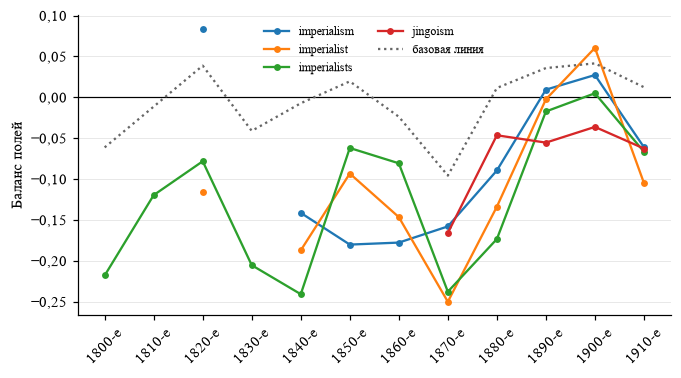

Сохранено: results/figures/fig1_imperial_balance.png


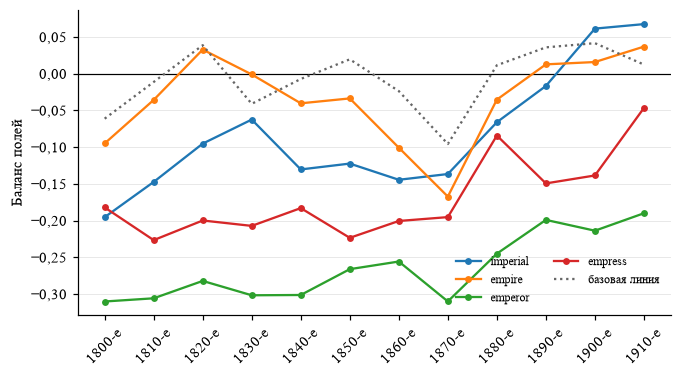

Сохранено: results/figures/04_political_balance_minus_baseline.png


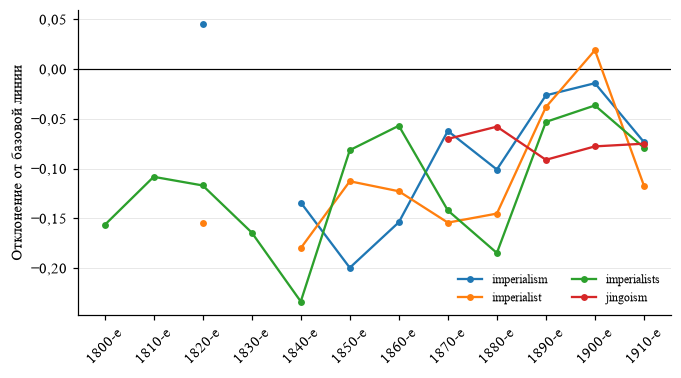

In [6]:
def plot_balance(table, words, filename, baseline=True, ylabel="Баланс полей"):
    fig, ax = T.figure(height_cm=9)
    ax.axhline(0,color="black",lw=.8)
    for w in words:
        ax.plot(x,table[w],marker="o",ms=3.5,label=w)
    if baseline:
        ax.plot(x,table["базовая_линия"],color="0.4",ls=":",label="базовая линия")
    ax.set_xticks(x, LABS, rotation=45); ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(T.COMMA); ax.legend(frameon=False,ncol=2,fontsize=8)
    fig.tight_layout(); T.save_fig(fig,filename); plt.show()

political = ["imperialism","imperialist","imperialists","jingoism"]
general = ["imperial","empire","emperor","empress"]
plot_balance(bal, political,"fig1_political_lexicon_balance")
plot_balance(bal, general,"fig1_imperial_balance")
plot_balance(dev,political,"04_political_balance_minus_baseline",False,"Отклонение от базовой линии")

## 3. Чувствительность к составу полей

Альтернативные поля включают названия стран и соответствующие прилагательные. В британском наборе *britain/british*, *england/english*, в иностранном — Франция, Австрия, Россия, Турция и Германия (существительные и прилагательные, в том числе *turkish* вместо *ottoman*). Не включаем колониальную лексику и имена монархов. Основные поля не заменяем. Сравниваем знак, величину и динамику обоих показателей; базовую линию рассчитываем заново для альтернативных полей. Различия — чувствительность к определению поля, а не статистическая ошибка.

Сохранено: results/tables/04_geographic_balance.csv
Сохранено: results/tables/04_geographic_balance_minus_baseline.csv
Сохранено: results/tables/04_field_sensitivity.csv
Сохранено: results/figures/04_geographic_political_balance.png


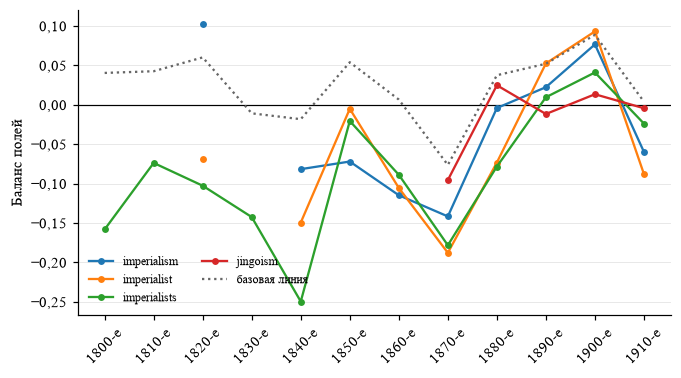

Сохранено: results/figures/04_geographic_general_balance.png


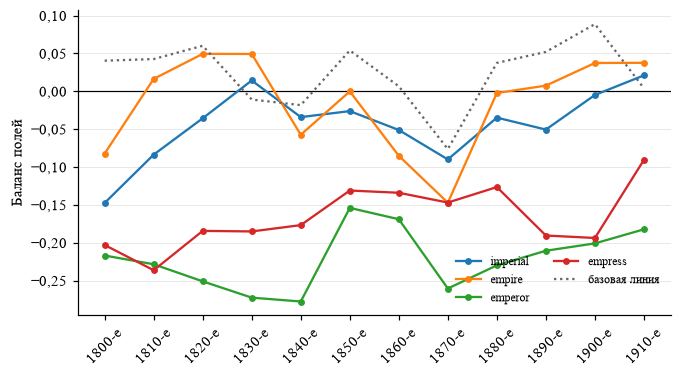

In [7]:
geo = balance_table(C.OWN_GEOGRAPHIC, C.FOREIGN_GEOGRAPHIC, "Географические поля")
geo_dev = geo[C.BALANCE_TARGETS].sub(geo["базовая_линия"],axis=0)
T.save_table(geo.round(4),"04_geographic_balance")
T.save_table(geo_dev.round(4),"04_geographic_balance_minus_baseline")
rows=[]
for lab in LABS:
    for w in C.BALANCE_TARGETS:
        rows.append({"десятилетие":lab,"слово":w,"основной":bal.loc[lab,w],"географический":geo.loc[lab,w],
                     "основной_минус_база":dev.loc[lab,w],"географический_минус_база":geo_dev.loc[lab,w]})
sensitivity=pd.DataFrame(rows)
sensitivity["разность_полей"] = sensitivity["географический"]-sensitivity["основной"]
T.save_table(sensitivity.round(4),"04_field_sensitivity",index=False)
plot_balance(geo,political,"04_geographic_political_balance")
plot_balance(geo,general,"04_geographic_general_balance")